## Week 2 – Data Cleaning & Pre-Processing

### 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler

### 2. Load the dataset

In [2]:
df = pd.read_excel("Raw Data Supermaket Sales.xlsx")

df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Month,Day,Year,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1,5,2019,2019-01-05,13:08:00,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3,8,2019,2019-03-08,10:29:00,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3,3,2019,2019-03-03,13:23:00,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1,27,2019,2019-01-27,20:33:00,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2,8,2019,2019-02-08,10:37:00,Ewallet,604.17,4.761905,30.2085,5.3


In [3]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 1000
Columns: 20


### 3. Initial data inspection

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Invoice ID               1000 non-null   object        
 1   Branch                   1000 non-null   object        
 2   City                     1000 non-null   object        
 3   Customer type            1000 non-null   object        
 4   Gender                   1000 non-null   object        
 5   Product line             1000 non-null   object        
 6   Unit price               1000 non-null   float64       
 7   Quantity                 1000 non-null   int64         
 8   Tax 5%                   1000 non-null   float64       
 9   Total                    1000 non-null   float64       
 10  Month                    1000 non-null   int64         
 11  Day                      1000 non-null   int64         
 12  Year                     1000 non-n

In [5]:
df.dtypes

Invoice ID                         object
Branch                             object
City                               object
Customer type                      object
Gender                             object
Product line                       object
Unit price                        float64
Quantity                            int64
Tax 5%                            float64
Total                             float64
Month                               int64
Day                                 int64
Year                                int64
Date                       datetime64[ns]
Time                               object
Payment                            object
cogs                              float64
gross margin percentage           float64
gross income                      float64
Rating                            float64
dtype: object

In [6]:
df.columns

Index(['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender',
       'Product line', 'Unit price', 'Quantity', 'Tax 5%', 'Total', 'Month',
       'Day', 'Year', 'Date', 'Time', 'Payment', 'cogs',
       'gross margin percentage', 'gross income', 'Rating'],
      dtype='object')

In [7]:
df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Month,Day,Year,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1,5,2019,2019-01-05,13:08:00,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3,8,2019,2019-03-08,10:29:00,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3,3,2019,2019-03-03,13:23:00,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1,27,2019,2019-01-27,20:33:00,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2,8,2019,2019-02-08,10:37:00,Ewallet,604.17,4.761905,30.2085,5.3


In [8]:
df.tail()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Month,Day,Year,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
995,233-67-5758,C,Naypyitaw,Normal,Male,Health and beauty,40.35,1,2.0175,42.3675,1,29,2019,2019-01-29,13:46:00,Ewallet,40.35,4.761905,2.0175,6.2
996,303-96-2227,B,Mandalay,Normal,Female,Home and lifestyle,97.38,10,48.6900,1022.4900,3,2,2019,2019-03-02,17:16:00,Ewallet,973.80,4.761905,48.6900,4.4
997,727-02-1313,A,Yangon,Member,Male,Food and beverages,31.84,1,1.5920,33.4320,2,9,2019,2019-02-09,13:22:00,Cash,31.84,4.761905,1.5920,7.7
998,347-56-2442,A,Yangon,Normal,Male,Home and lifestyle,65.82,1,3.2910,69.1110,2,22,2019,2019-02-22,15:33:00,Cash,65.82,4.761905,3.2910,4.1
999,849-09-3807,A,Yangon,Member,Female,Fashion accessories,88.34,7,30.9190,649.2990,2,18,2019,2019-02-18,13:28:00,Cash,618.38,4.761905,30.9190,6.6


In [9]:
df.describe()

,Unit price,Quantity,Tax 5%,Total,Month,Day,Year,Date,cogs,gross margin percentage,gross income,Rating
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.0,1000,1000.00000,1.000000e+03,1000.000000,1000.00000
mean,55.672130,5.510000,15.379369,322.966749,1.993000,15.256000,2019.0,2019-02-14 00:05:45.600000,307.58738,4.761905e+00,15.379369,6.97270
min,10.080000,1.000000,0.508500,10.678500,1.000000,1.000000,2019.0,2019-01-01 00:00:00,10.17000,4.761905e+00,0.508500,4.00000
25%,32.875000,3.000000,5.924875,124.422375,1.000000,8.000000,2019.0,2019-01-24 00:00:00,118.49750,4.761905e+00,5.924875,5.50000
50%,55.230000,5.000000,12.088000,253.848000,2.000000,15.000000,2019.0,2019-02-13 00:00:00,241.76000,4.761905e+00,12.088000,7.00000
75%,77.935000,8.000000,22.445250,471.350250,3.000000,23.000000,2019.0,2019-03-08 00:00:00,448.90500,4.761905e+00,22.445250,8.50000
max,99.960000,10.000000,49.650000,1042.650000,3.000000,31.000000,2019.0,2019-03-30 00:00:00,993.00000,4.761905e+00,49.650000,10.00000
std,26.494628,2.923431,11.708825,245.885335,0.835254,8.693563,0.0,NaN,234.17651,6.131498e-14,11.708825,1.71858


In [10]:
df.describe(include="object")

,Invoice ID,Branch,City,Customer type,Gender,Product line,Time,Payment
count,1000,1000,1000,1000,1000,1000,1000,1000
unique,1000,3,3,2,2,6,506,3
top,750-67-8428,A,Yangon,Member,Female,Fashion accessories,19:48:00,Ewallet
freq,1,340,340,501,501,178,7,345


### 4. Check missing values

In [11]:
missing_values = df.isnull().sum()

print(missing_values)

Invoice ID                 0
Branch                     0
City                       0
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Total                      0
Month                      0
Day                        0
Year                       0
Date                       0
Time                       0
Payment                    0
cogs                       0
gross margin percentage    0
gross income               0
Rating                     0
dtype: int64


In [12]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

Invoice ID                 0.0
Branch                     0.0
City                       0.0
Customer type              0.0
Gender                     0.0
Product line               0.0
Unit price                 0.0
Quantity                   0.0
Tax 5%                     0.0
Total                      0.0
Month                      0.0
Day                        0.0
Year                       0.0
Date                       0.0
Time                       0.0
Payment                    0.0
cogs                       0.0
gross margin percentage    0.0
gross income               0.0
Rating                     0.0
dtype: float64


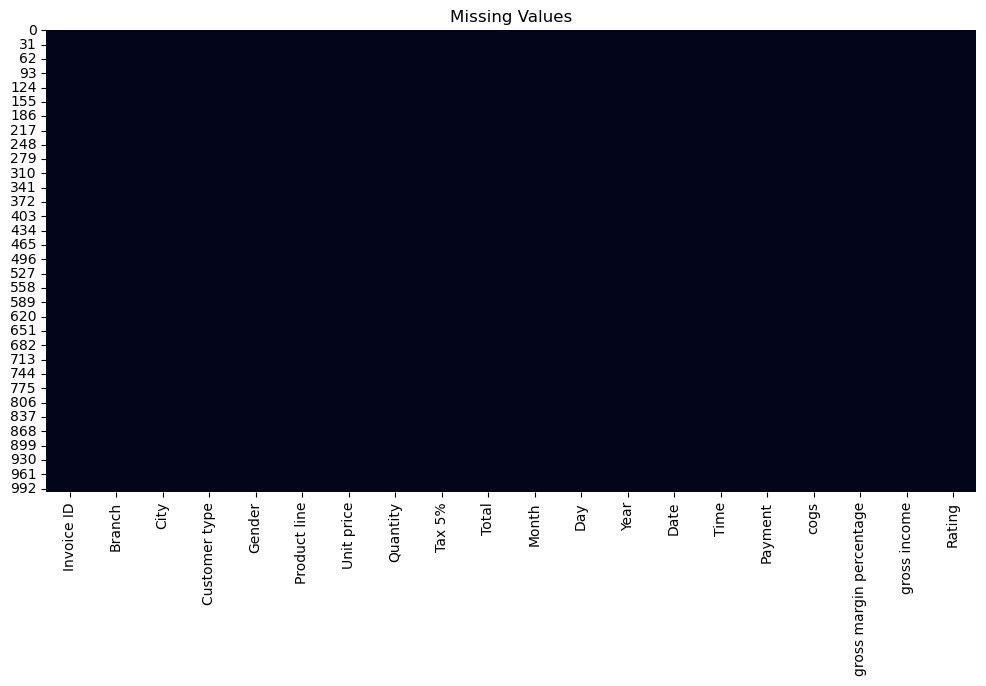

In [13]:
plt.figure(figsize=(12,6))

sns.heatmap(df.isnull(), cbar=False)

plt.title("Missing Values")
plt.show()

In [14]:
numeric_columns = df.select_dtypes(include=np.number).columns

for column in numeric_columns:
    df[column] = df[column].fillna(df[column].median())

In [15]:
categorical_columns = df.select_dtypes(include="object").columns

for column in categorical_columns:
    df[column] = df[column].fillna(df[column].mode()[0])

In [16]:
print(df.isnull().sum().sum())

0


### 5. Check duplicate rows

In [17]:
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


In [18]:
df = df.drop_duplicates()

### 6. Check duplicate Invoice IDs

In [19]:
print("Duplicate Invoice IDs:",
      df["Invoice ID"].duplicated().sum())

Duplicate Invoice IDs: 0


In [20]:
df[df["Invoice ID"].duplicated(keep=False)]

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Month,Day,Year,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating


### 7. Check unique categorical values

In [21]:
print("Branches:")
print(df["Branch"].unique())


Branches:
['A' 'C' 'B']


In [22]:
print("\nCities:")
print(df["City"].unique())



Cities:
['Yangon' 'Naypyitaw' 'Mandalay']


In [23]:
print("\nProduct Lines:")
print(df["Product line"].unique())


Product Lines:
['Health and beauty' 'Electronic accessories' 'Home and lifestyle'
 'Sports and travel' 'Food and beverages' 'Fashion accessories']


In [24]:
print("\nCustomer Types:")
print(df["Customer type"].unique())



Customer Types:
['Member' 'Normal']


In [25]:
print("\nGender:")
print(df["Gender"].unique())


Gender:
['Female' 'Male']


In [26]:
print("\nPayment Methods:")
print(df["Payment"].unique())


Payment Methods:
['Ewallet' 'Cash' 'Credit card']


### 8. Check inconsistent categorical values

In [27]:
categorical_columns = [
    "Branch",
    "City",
    "Customer type",
    "Gender",
    "Product line",
    "Payment"
]

for column in categorical_columns:
    print("\n", column)
    print(df[column].value_counts())


 Branch
Branch
A    340
B    332
C    328
Name: count, dtype: int64

 City
City
Yangon       340
Mandalay     332
Naypyitaw    328
Name: count, dtype: int64

 Customer type
Customer type
Member    501
Normal    499
Name: count, dtype: int64

 Gender
Gender
Female    501
Male      499
Name: count, dtype: int64

 Product line
Product line
Fashion accessories       178
Food and beverages        174
Electronic accessories    170
Sports and travel         166
Home and lifestyle        160
Health and beauty         152
Name: count, dtype: int64

 Payment
Payment
Ewallet        345
Cash           344
Credit card    311
Name: count, dtype: int64


In [28]:
for column in categorical_columns:
    df[column] = df[column].astype(str).str.strip()

### 9. Check impossible numerical values

In [29]:
print(df[df["Quantity"] <= 0])

Empty DataFrame
Columns: [Invoice ID, Branch, City, Customer type, Gender, Product line, Unit price, Quantity, Tax 5%, Total, Month, Day, Year, Date, Time, Payment, cogs, gross margin percentage, gross income, Rating]
Index: []


In [30]:
print(df[df["Unit price"] <= 0])

Empty DataFrame
Columns: [Invoice ID, Branch, City, Customer type, Gender, Product line, Unit price, Quantity, Tax 5%, Total, Month, Day, Year, Date, Time, Payment, cogs, gross margin percentage, gross income, Rating]
Index: []


In [31]:
print(df[df["Total"] <= 0])

Empty DataFrame
Columns: [Invoice ID, Branch, City, Customer type, Gender, Product line, Unit price, Quantity, Tax 5%, Total, Month, Day, Year, Date, Time, Payment, cogs, gross margin percentage, gross income, Rating]
Index: []


In [32]:
print(df[(df["Rating"] < 1) | (df["Rating"] > 10)])

Empty DataFrame
Columns: [Invoice ID, Branch, City, Customer type, Gender, Product line, Unit price, Quantity, Tax 5%, Total, Month, Day, Year, Date, Time, Payment, cogs, gross margin percentage, gross income, Rating]
Index: []


### 10. Convert Date column

In [33]:
df["Date"] = pd.to_datetime(df["Date"])

In [34]:
print(df["Date"].dtype)

datetime64[ns]


In [35]:
df["Year"] = df["Date"].dt.year

### 11. Feature Engineering

In [36]:
df["Month_Number"] = df["Date"].dt.month

In [37]:
df["Month_Name"] = df["Date"].dt.month_name()

In [38]:
df["Day_Number"] = df["Date"].dt.day

In [39]:
df["Day_of_Week"] = df["Date"].dt.day_name()

### 12. Create a profit-related feature

In [40]:
df["Profit_Per_Unit"] = df["gross income"] / df["Quantity"]

In [41]:
df[["Quantity", "gross income", "Profit_Per_Unit"]].head()

,Quantity,gross income,Profit_Per_Unit
0,7,26.1415,3.7345
1,5,3.8200,0.7640
2,7,16.2155,2.3165
3,8,23.2880,2.9110
4,7,30.2085,4.3155


### 13. Create a high-value transaction feature

In [42]:
median_total = df["Total"].median()

df["High_Value_Transaction"] = np.where(
    df["Total"] > median_total,
    1,
    0
)

In [43]:
df["High_Value_Transaction"].value_counts()

High_Value_Transaction
1    500
0    500
Name: count, dtype: int64

### 14. Detect outliers using IQR

In [44]:
Q1 = df["Total"].quantile(0.25)

Q3 = df["Total"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR

upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

Q1: 124.422375
Q3: 471.35024999999996
IQR: 346.927875
Lower limit: -395.9694375
Upper limit: 991.7420625


In [45]:
outliers = df[
    (df["Total"] < lower_limit) |
    (df["Total"] > upper_limit)
]

print("Number of outliers:", len(outliers))

Number of outliers: 9


### 15. Visualize outliers using boxplot

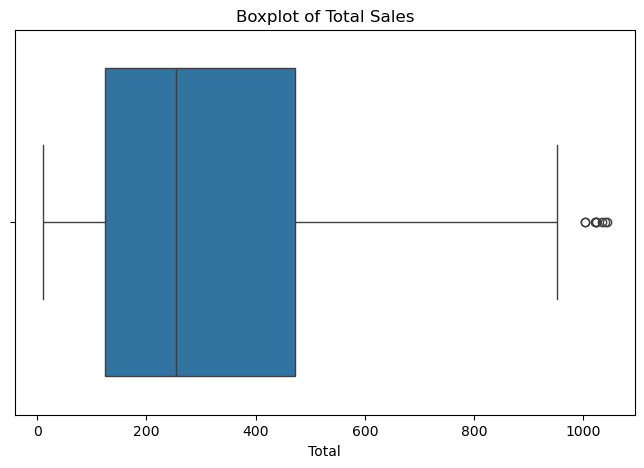

In [46]:
plt.figure(figsize=(8,5))

sns.boxplot(x=df["Total"])

plt.title("Boxplot of Total Sales")

plt.show()

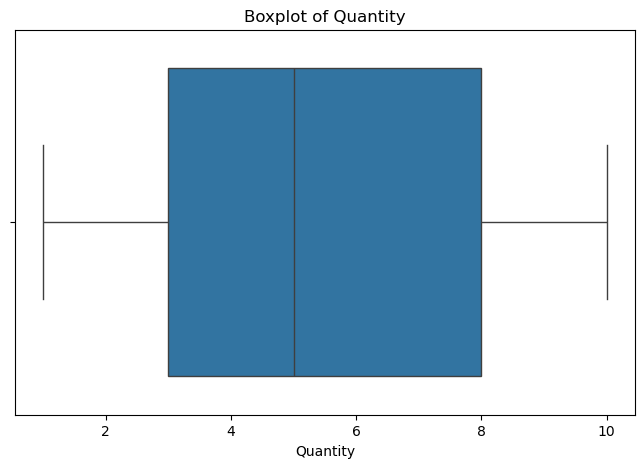

In [47]:
plt.figure(figsize=(8,5))

sns.boxplot(x=df["Quantity"])

plt.title("Boxplot of Quantity")

plt.show()

### 16. Handling outliers

In [48]:
outliers[[
    "Invoice ID",
    "Product line",
    "Quantity",
    "Unit price",
    "Total"
]]

,Invoice ID,Product line,Quantity,Unit price,Total
166,234-65-2137,Home and lifestyle,10,95.58,1003.590
167,687-47-8271,Fashion accessories,10,98.98,1039.290
350,860-79-0874,Fashion accessories,10,99.30,1042.650
357,554-42-2417,Sports and travel,10,95.44,1002.120
422,271-88-8734,Fashion accessories,10,97.21,1020.705
557,283-26-5248,Food and beverages,10,98.52,1034.460
699,751-41-9720,Home and lifestyle,10,97.50,1023.750
792,744-16-7898,Home and lifestyle,10,97.37,1022.385
996,303-96-2227,Home and lifestyle,10,97.38,1022.490


In [49]:
df["Total_Capped"] = df["Total"].clip(
    lower=lower_limit,
    upper=upper_limit
)

In [50]:
df[["Total", "Total_Capped"]].head()

,Total,Total_Capped
0,548.9715,548.9715
1,80.2200,80.2200
2,340.5255,340.5255
3,489.0480,489.0480
4,634.3785,634.3785


### 17. Select numerical features

In [51]:
numeric_features = [
    "Unit price",
    "Quantity",
    "Tax 5%",
    "cogs",
    "gross income",
    "Rating"
]

X_numeric = df[numeric_features]

X_numeric.head()

,Unit price,Quantity,Tax 5%,cogs,gross income,Rating
0,74.69,7,26.1415,522.83,26.1415,9.1
1,15.28,5,3.8200,76.40,3.8200,9.6
2,46.33,7,16.2155,324.31,16.2155,7.4
3,58.22,8,23.2880,465.76,23.2880,8.4
4,86.31,7,30.2085,604.17,30.2085,5.3


### 18. Standardization

In [52]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_numeric)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=numeric_features
)

X_scaled.head()

,Unit price,Quantity,Tax 5%,cogs,gross income,Rating
0,0.718160,0.509930,0.919607,0.919607,0.919607,1.238443
1,-1.525303,-0.174540,-0.987730,-0.987730,-0.987730,1.529527
2,-0.352781,0.509930,0.071446,0.071446,0.071446,0.248760
3,0.096214,0.852165,0.675780,0.675780,0.675780,0.830927
4,1.156959,0.509930,1.267125,1.267125,1.267125,-0.973790


In [53]:
X_scaled.describe()

,Unit price,Quantity,Tax 5%,cogs,gross income,Rating
count,1.000000e+03,1.000000e+03,1.000000e+03,1.000000e+03,1.000000e+03,1.000000e+03
mean,-1.065814e-16,6.394885e-17,1.243450e-16,1.776357e-17,1.243450e-16,1.882938e-16
std,1.000500e+00,1.000500e+00,1.000500e+00,1.000500e+00,1.000500e+00,1.000500e+00
min,-1.721668e+00,-1.543480e+00,-1.270692e+00,-1.270692e+00,-1.270692e+00,-1.730607e+00
25%,-8.608740e-01,-8.590099e-01,-8.078714e-01,-8.078714e-01,-8.078714e-01,-8.573570e-01
50%,-1.669588e-02,-1.745399e-01,-2.812422e-01,-2.812422e-01,-2.812422e-01,1.589315e-02
75%,8.406991e-01,8.521652e-01,6.037682e-01,6.037682e-01,6.037682e-01,8.891433e-01
max,1.672416e+00,1.536635e+00,2.928371e+00,2.928371e+00,2.928371e+00,1.762394e+00


### 19. Encoding categorical variables

In [54]:
categorical_features = [
    "Branch",
    "City",
    "Customer type",
    "Gender",
    "Product line",
    "Payment"
]

X_categorical = pd.get_dummies(
    df[categorical_features],
    drop_first=True
)

X_categorical.head()

,Branch_B,Branch_C,City_Naypyitaw,City_Yangon,Customer type_Normal,Gender_Male,Product line_Fashion accessories,Product line_Food and beverages,Product line_Health and beauty,Product line_Home and lifestyle,Product line_Sports and travel,Payment_Credit card,Payment_Ewallet
0,False,False,False,True,False,False,False,False,True,False,False,False,True
1,False,True,True,False,True,False,False,False,False,False,False,False,False
2,False,False,False,True,True,True,False,False,False,True,False,True,False
3,False,False,False,True,False,True,False,False,True,False,False,False,True
4,False,False,False,True,True,True,False,False,False,False,True,False,True


### 20. Combine numerical and categorical features

In [55]:
X_final = pd.concat(
    [X_scaled, X_categorical],
    axis=1
)

In [56]:
X_final.head()

,Unit price,Quantity,Tax 5%,cogs,gross income,Rating,Branch_B,Branch_C,City_Naypyitaw,City_Yangon,Customer type_Normal,Gender_Male,Product line_Fashion accessories,Product line_Food and beverages,Product line_Health and beauty,Product line_Home and lifestyle,Product line_Sports and travel,Payment_Credit card,Payment_Ewallet
0,0.718160,0.509930,0.919607,0.919607,0.919607,1.238443,False,False,False,True,False,False,False,False,True,False,False,False,True
1,-1.525303,-0.174540,-0.987730,-0.987730,-0.987730,1.529527,False,True,True,False,True,False,False,False,False,False,False,False,False
2,-0.352781,0.509930,0.071446,0.071446,0.071446,0.248760,False,False,False,True,True,True,False,False,False,True,False,True,False
3,0.096214,0.852165,0.675780,0.675780,0.675780,0.830927,False,False,False,True,False,True,False,False,True,False,False,False,True
4,1.156959,0.509930,1.267125,1.267125,1.267125,-0.973790,False,False,False,True,True,True,False,False,False,False,True,False,True


In [57]:
print("Final number of features:",
      X_final.shape[1])

Final number of features: 19


### 21. Check final dataset

In [58]:
print("Shape:", X_final.shape)

print("\nMissing values:")
print(X_final.isnull().sum().sum())

print("\nDuplicate rows:")
print(X_final.duplicated().sum())

Shape: (1000, 19)

Missing values:
0

Duplicate rows:
0


### 22. Save cleaned dataset

In [59]:
df.to_csv(
    "Supermarket_Sales_Cleaned.csv",
    index=False
)

In [60]:
X_final.to_csv(
    "Supermarket_Sales_ML_Ready.csv",
    index=False
)

### 23. Final data-quality report

In [61]:
print("========== FINAL DATA QUALITY REPORT ==========")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("Missing values:",
      df.isnull().sum().sum())

print("Duplicate rows:",
      df.duplicated().sum())

print("Invalid Quantity:",
      (df["Quantity"] <= 0).sum())

print("Invalid Unit Price:",
      (df["Unit price"] <= 0).sum())

print("Invalid Total:",
      (df["Total"] <= 0).sum())

print("Invalid Rating:",
      ((df["Rating"] < 1) | (df["Rating"] > 10)).sum())

print("IQR Outliers:",
      len(outliers))

========== FINAL DATA QUALITY REPORT ==========
Rows: 1000
Columns: 27
Missing values: 0
Duplicate rows: 0
Invalid Quantity: 0
Invalid Unit Price: 0
Invalid Total: 0
Invalid Rating: 0
IQR Outliers: 9
